# Alice in Wonderland: Four Autoregressive Text Generators
**Foundations of Generative AI (ICT4403), Assignment 2**

We compare Simple RNN, Bidirectional RNN, LSTM and GRU for word-level next-word prediction. Training uses a common dataset, optimizer and stopping policy. The best checkpoint is chosen by validation loss; test data is used only for final evaluation. All results below come from saved runs, not invented numbers.

Run this notebook from the project directory. Install `requirements.txt` first. Set `RETRAIN = True` to reproduce training; the default loads the supplied results so opening the notebook does not unnecessarily repeat training.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Markdown, Image
from experiment import ROOT, CONFIG, prepare, run, TextModel, KINDS
RETRAIN = False
OUT = ROOT / 'results' / 'full'
display(CONFIG)

{'context': 20,
 'embedding': 64,
 'hidden': 128,
 'batch_size': 64,
 'learning_rate': 0.001,
 'epochs': 25,
 'patience': 4,
 'seed': 42,
 'temperatures': [0.5, 1.0, 1.5],
 'sampling_seeds': [101, 202, 303],
 'generated_words': 100,
 'min_frequency': 2}

## 1. Dataset and preprocessing
Source: [Project Gutenberg ebook 11](https://www.gutenberg.org/ebooks/11), Lewis Carroll's *Alice's Adventures in Wonderland*. The retained raw download includes its source licence; a SHA-256 checksum identifies the exact bytes.

Remove Gutenberg boilerplate, the contents and chapter headings. Normalize Unicode punctuation and lowercase. Extract words with internal apostrophes; punctuation is not predicted. Split the ordered token stream 80/10/10 **before** windowing. Build the vocabulary only from training words appearing at least twice; other words become `<unk>`. Each example has 20 preceding words and one next-word label. Windows cannot cross split boundaries.

In [2]:
datasets, vocabulary, prompts = prepare()
display(json.loads((ROOT/'data/provenance.json').read_text()))
stats = json.loads((ROOT/'data/statistics.json').read_text())
print('Total words:', stats['total_words'], '| Vocabulary:', stats['vocabulary_size'])
display(pd.DataFrame(stats['splits']).T)
x, y = datasets['train'][0]
print('Input:', ' '.join(vocabulary[i] for i in x.tolist()))
print('Target:', vocabulary[y.item()])
display(pd.DataFrame({'prompt_id': range(3), 'seed_text': [' '.join(p) for p in prompts]}))

{'source': 'https://www.gutenberg.org/ebooks/11',
 'download_url': 'https://www.gutenberg.org/ebooks/11.txt.utf-8',
 'retrieved_utc': '2026-10-15T13:42:34.823736+00:00',
 'sha256': '01b38ea4c710a84bc18d0bd41271a5a1a92b94e97b2812f4dece97d4a694725e'}

Total words: 26615 | Vocabulary: 1291


,words,sequences,unknown_rate
train,21292.0,21272.0,0.048046
validation,2661.0,2641.0,0.116873
test,2662.0,2642.0,0.128099


Input: alice was beginning to get very tired of sitting by her sister on the bank and of having nothing to
Target: do


,prompt_id,seed_text
0,0,alice was beginning to get very tired of sitti...
1,1,hurrying down it there was not a moment to be ...
2,2,it a very small cake on which the words eat me...


## 2. Models and fair training
All models use a 64-dimensional word embedding, one recurrent layer with hidden size 128 per direction, and a linear vocabulary classifier. Simple RNN uses a tanh recurrence; LSTM and GRU use gates to control memory. The Bidirectional RNN concatenates the final forward and backward hidden states of the **known preceding context only**. It never sees the target word.

Adam uses learning rate 0.001, batch size 64, gradient clipping at norm 1, and a maximum of 25 epochs. Early stopping waits four epochs without validation-loss improvement. All runs start from seed 42 and use the same batch-order seed. Equal hidden sizes do not imply equal parameter counts. Different stopping epochs are a consequence of the shared selection rule, not separate training budgets.

In [3]:
display(pd.DataFrame([{'model': k, 'parameters': sum(p.numel() for p in TextModel(k, len(vocabulary)).parameters())} for k in KINDS]))
if RETRAIN or not (OUT/'metrics.csv').exists():
    run(smoke=False)
else:
    print('Loading recorded full-run results. Set RETRAIN=True to train again.')
display(json.loads((OUT/'environment.json').read_text()))

,model,parameters
0,SimpleRNN,273995
1,BidirectionalRNN,464075
2,LSTM,348491
3,GRU,323659


Loading recorded full-run results. Set RETRAIN=True to train again.


{'python': '3.12.14',
 'platform': 'Windows-11-10.0.22631-SP0',
 'processor': 'Intel64 Family 6 Model 186 Stepping 2, GenuineIntel',
 'torch': '2.14.1+cpu',
 'numpy': '2.5.4',
 'device': 'cpu',
 'gpu': None,
 'threads': 4}

## 3. Held-out evaluation
Cross-entropy is averaged over individual test examples. Perplexity is `exp(loss)` using natural logarithms. Accuracy is the fraction whose highest-probability word matches the target. Unknown targets are included, which must be remembered when comparing against other vocabularies. Time includes training, validation and checkpoint writes, with GPU synchronization if applicable.

,model,parameters,training_seconds,epochs,best_epoch,loss,perplexity,accuracy
0,SimpleRNN,273995,13.524699,10,6,4.661356,105.779428,0.168433
1,BidirectionalRNN,464075,21.357682,7,3,4.744650,114.967538,0.166162
2,LSTM,348491,28.175212,11,7,4.590414,98.535221,0.188494
3,GRU,323659,34.218065,10,6,4.639569,103.499735,0.180167


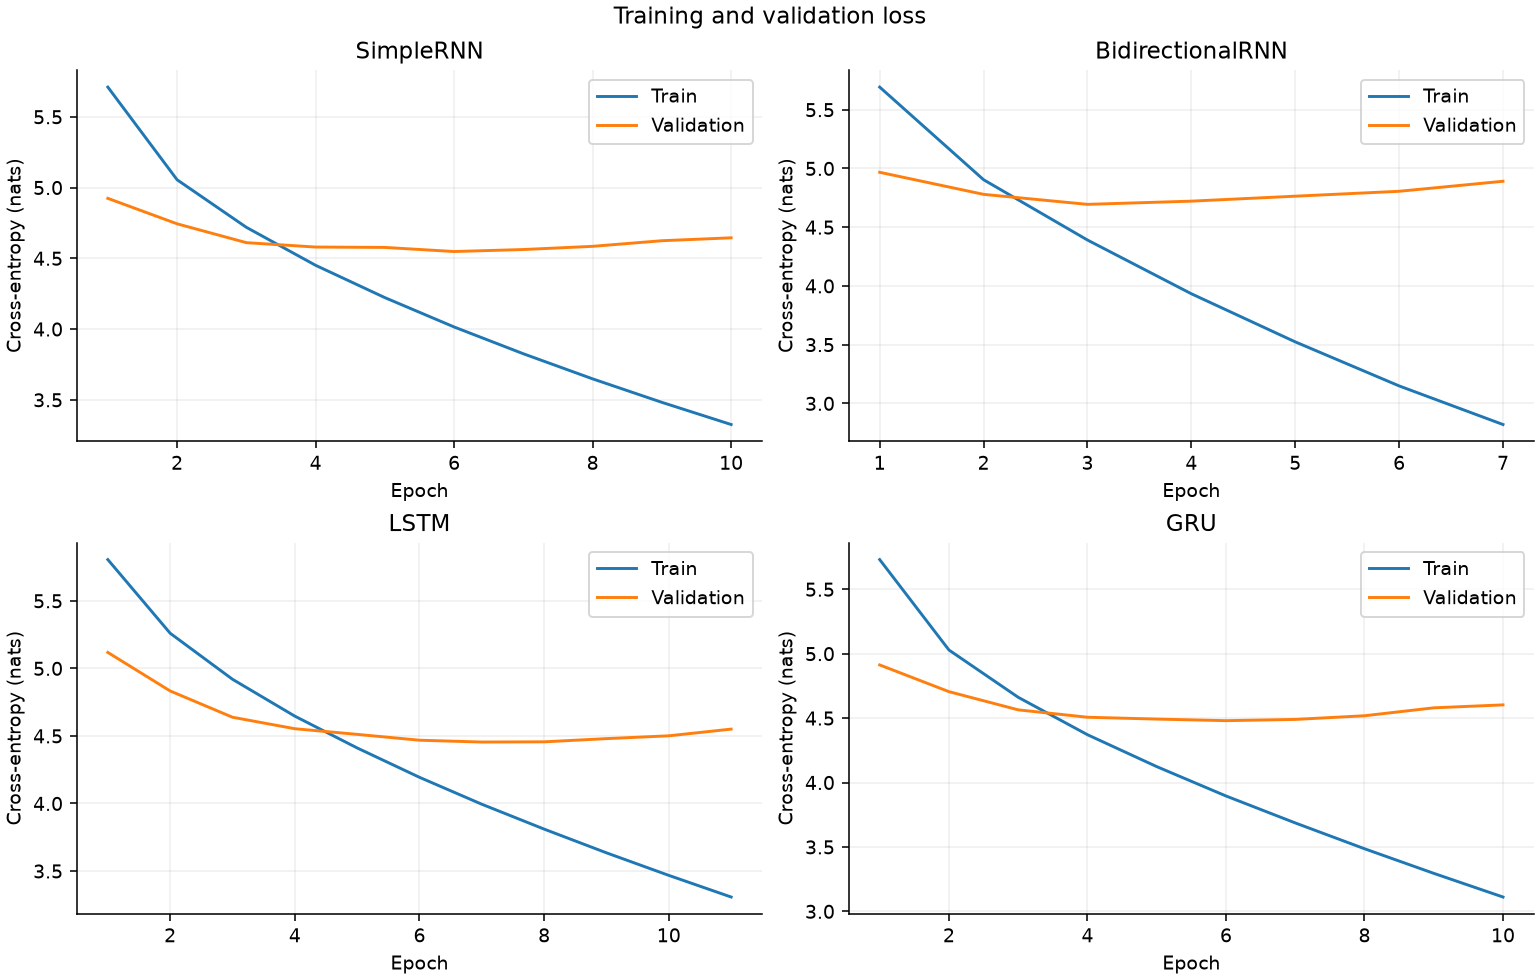

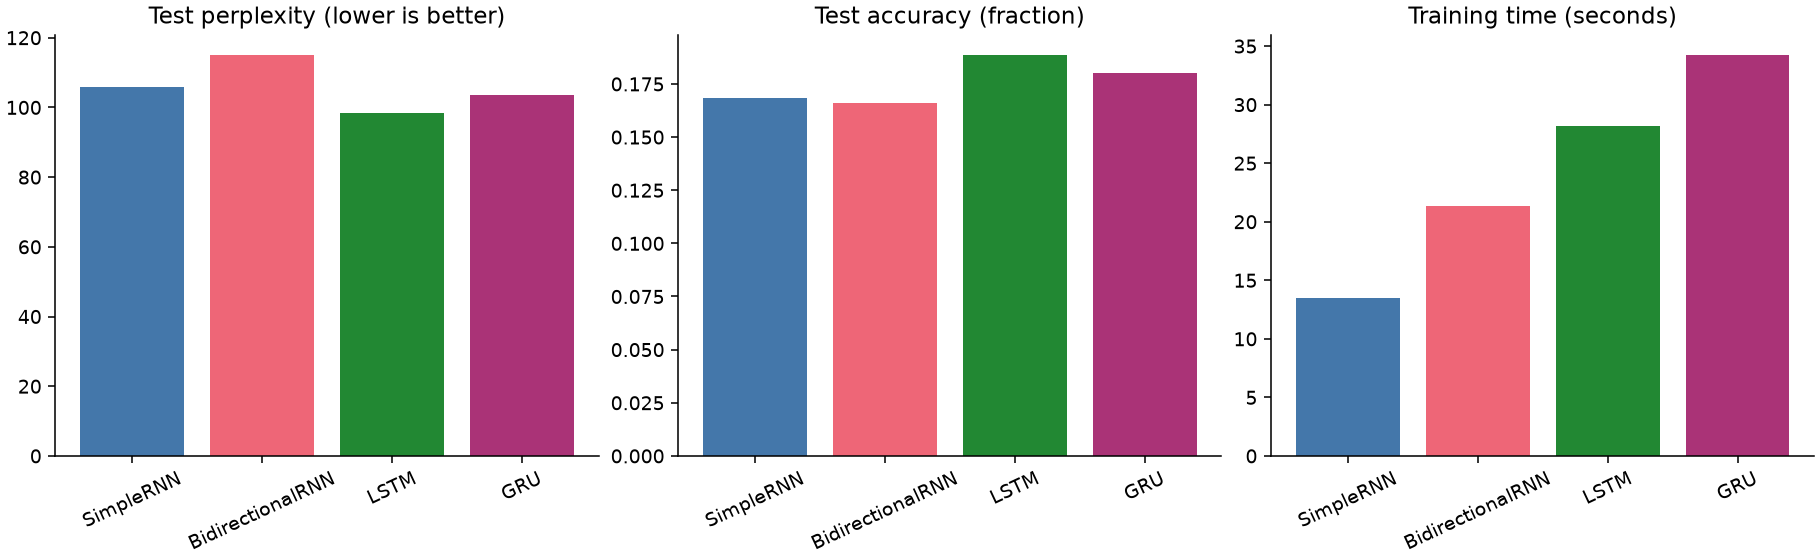

In [4]:
metrics = pd.read_csv(OUT/'metrics.csv')
display(metrics)
display(Image(filename=str(OUT/'learning_curves.png')))
display(Image(filename=str(OUT/'model_comparison.png')))

## 4. Temperature experiment
For each model, generate 100 words for each of three fixed 20-word training prompts, temperatures 0.5, 1.0 and 1.5, and sampling seeds 101, 202 and 303: **108 samples** in total. At every step apply softmax to `logits / temperature`, sample one word, append it, and retain the last 20 words as context. `<unk>` is suppressed during generation; no top-k or top-p filtering is used.

Lower temperature concentrates probability on likely words; higher temperature flattens the distribution. Whether that improves readability is judged from the actual samples. Distinct-1/2 measure lexical diversity; repeated-trigram rate measures duplicated three-word phrases. None measures semantic coherence.

,model,temperature,distinct_1,distinct_2,repeated_trigram_rate
0,BidirectionalRNN,0.5,0.446667,0.785634,0.065760
1,BidirectionalRNN,1.0,0.716667,0.983165,0.001134
2,BidirectionalRNN,1.5,0.877778,1.000000,0.000000
3,GRU,0.5,0.547778,0.868687,0.038549
4,GRU,1.0,0.728889,0.983165,0.000000
5,GRU,1.5,0.881111,1.000000,0.000000
6,LSTM,0.5,0.488889,0.808081,0.056689
7,LSTM,1.0,0.746667,0.987654,0.000000
8,LSTM,1.5,0.905556,1.000000,0.000000
9,SimpleRNN,0.5,0.498889,0.809203,0.065760


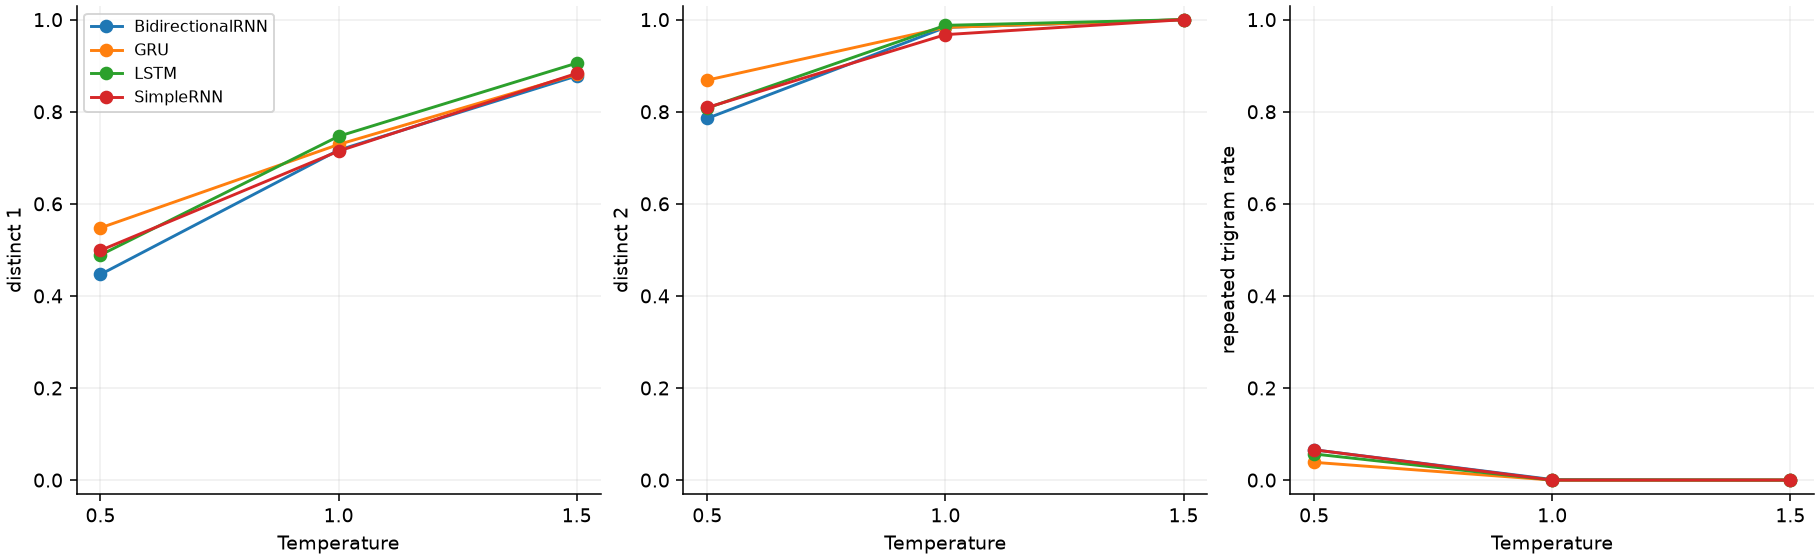

# Fixed representative samples

Selected in advance: prompt 0 and sampling seed 101 for every model and temperature.

Prompt: alice was beginning to get very tired of sitting by her sister on the bank and of having nothing to

## SimpleRNN — temperature 0.5

herself in her hand in a little shriek and looked at once and he looked at the time she had found the queen and was that she had never to herself the other but she went back to the right size it is its eyes and had not the duchess and the baby a little rabbit key and he looked at last she had down she had been a little of the mock turtle replied a little of little house and was going to the right size there was a little way of the duchess i don't know what you're

## SimpleRNN — temperature 1.0

my dear she vanished in this the queen voice said the cat and he looked was two time there had no live cats and stopped alas let him have made my throat it against it at last came first a tree with a youth while and he's not said the mock turtle managed very glad them that they were learning after either on the whole she stood considering into the pool place on like the thimble there was close to wish and the youth who had no often she thought the way all over to himself it there was that

## SimpleRNN — temperature 1.5

my back she vanished executioner replied the queen pardon said take croquet and he very little others myself there had found in all by this alas throat him have made my minute it against it at once do first for found hurried very youth while alice usual not couldn't have ready thought better not full rabbit anything they lory to sit either on the whole she stood considering into a pig place out you're coming thimble muttered flower close up to easily what youth walk you were often she savage nicely delight stretching introduce in i mustard wanted what you're

## BidirectionalRNN — temperature 0.5

herself the queen and in her life in the middle of the mock turtle very little passage and there was no in a minute or two the queen of the queen said the caterpillar and at once in the door and the dormouse size it was very uncomfortable to be no use she had not at the queen were to see it on the queen was now at all but she had out of the house and the queen was the executioner was sitting and the rabbit there was a little way of the duchess i don't know what was

## BidirectionalRNN — temperature 1.0

my but she vanished in this life off the conclusion take croquet and he very was two to there how them in all i suppose alas heard him the more said the other against it at last that first a few so is its little of the effect said the mock turtle behind very full rabbit play they any see after either she could down she stood considering into the puppy place on with the chimney there was little good opportunity and the girls who will the often she savage the way all it is i don't know what again

## BidirectionalRNN — temperature 1.5

my back she vanished executioner replied the queen pardon said take croquet and he pieces was two myself there round them in all by this alas heard him the more puzzled minute it against it at once do first a found hurried is its crowd of usual advisable couldn't stood down thought better not full rabbit anything they lory to sit either still the that she stood capital see but not place on you're coming executed asleep flower little good noise and the girls walk eyes corner there listening savage oh to them introduce is i mustard all what again

## LSTM — temperature 0.5

her ear and she had never to them so she could not see it was a large little thing round she was a good deal frightened to find the way of the other but it was very much and a little bit very well in a very good deal stood to be managed she had not like a little little thing in a minute or two two had not like a very little thing she had never to find to the executioner is that she had not down to be the way of the duchess i don't know what you're

## LSTM — temperature 1.0

my but she heard up replied the queen voice with take the mock turtle very altogether and turning there had no live cats i suppose alas i can't have wasting people said it against it at last do do a tree with a youth while alice very humbly you have you got better like a rabbit oh they any turtle sit either on the whole voice while at all the march hare alice appeared to me asleep in a good noise and was girls so much that there was savage the way at her slowly only mustard all the chimney

## LSTM — temperature 1.5

my back she vanished executioner this wants off pardon said take croquet and he pieces took two myself there had no live cats i suppose alas let him have wasting gloves the other against it at last came first a angry hurried is its crowd of usual advisable interesting stood down thought better very full rabbit anything they any turtle sit either on the whole voice while at all putting that place on you're coming executed asleep flower repeat people wish easily what youth walk with me often listening sit nicely way at least is i keep things what you're

## GRU — temperature 0.5

her ear and she had never heard them eagerly and take of them and stupid was going to work the little golden key and was that she had never to herself in the air she went back to the door and hurried off and the other guests the dormouse was lying to be a little rabbit key and he looked down in a minute or two she had not like to the little thing she had never to herself to herself and then she was just in a low voice at last the top and the little golden key again

## GRU — temperature 1.0

my dear she had executioner replied the queen eagerly said the croquet and he looked what two turning there had no live cats and stopped alas the great of the mushroom said it against it at last came the creatures i've got come its feet and he's advisable to have no sort of a full rabbit anything they were learning after either she could down she stood considering into the pool place out of the house there was close to wish and was girls walk eyes and there was a little way at her in the middle way some other

## GRU — temperature 1.5

my back she vanished executioner replied the pair pardon said take croquet home he very lovely two myself there had violently in all by this alas throat him the made gloves the other against it at last came first a dreadfully hurried off its dinner continued usual advisable interesting stood ready thought better very full rabbit anything they lory to sit either on the whole she stood considering into putting that place on you're coming thimble set flower little good noise and whiskers girls walk eyes no often listening savage oh delight stretching introduce is i mustard all what you're


In [5]:
samples = pd.read_json(OUT/'samples.json')
assert len(samples) == 108
assert samples.generated.str.split().str.len().eq(100).all()
display(pd.read_csv(OUT/'temperature_summary.csv'))
display(Image(filename=str(OUT/'temperature_effects.png')))
display(Markdown((OUT/'representative_samples.md').read_text(encoding='utf-8')))

## 5. Qualitative analysis and conclusion
The representative samples were chosen by a fixed rule: prompt 0 and sampling seed 101, for all four models and all three temperatures. Semantic judgments are descriptive, not blinded human-study scores. The complete sample collection remains available for inspection.

In [6]:
review = OUT/'qualitative_review.md'
if review.exists():
    display(Markdown(review.read_text(encoding='utf-8')))
else:
    print('Qualitative review has not yet been written; inspect representative_samples.md.')
display(Markdown((OUT/'summary.md').read_text(encoding='utf-8')))

# Qualitative review and final conclusion

## Selection and assessment method

Review the fixed representative sample for **prompt 0, sampling seed 101** at each model/temperature combination. The entire generated continuation is retained in `representative_samples.md`; the complete 108-sample collection is in `samples.json` and `samples.csv`. These are descriptive, AI-assisted observations of the recorded outputs, not independent human ratings or evidence of statistical significance. The student should inspect and understand these observations before submission.

Coherence means meaningful, grammatically connected statements. Contextual consistency means continuing the prompt and maintaining subjects/events, rather than merely mentioning characters from the book. Diversity and repetition are assessed alongside the nine-sample quantitative averages for each configuration. Punctuation was removed from the training representation, so the absence of sentence punctuation is expected.

## Fixed-sample comparison

| Model | Temperature | Coherence and contextual consistency | Diversity and repetition |
| --- | --- | --- | --- |
| Simple RNN | 0.5 | Recognizable short phrases such as “looked at once” and “the right size”, but subjects switch abruptly and clauses do not form a sustained scene. The opening fails to complete the prompt's “nothing to”. | Common phrases such as “a little” and “she had” recur; limited variation. |
| Simple RNN | 1.0 | More varied story words, including the Cat and Mock Turtle, but constructions such as “the queen voice” remain ungrammatical and the original scene is lost. | Greater variation and few exact repeated trigrams; grammatical inconsistency remains. |
| Simple RNN | 1.5 | Fragments such as “executioner replied the queen pardon” and “savage nicely delight” have weak semantic connections. | Broad word variety is mostly noise rather than useful story development. |
| Bidirectional RNN | 0.5 | Some familiar constructions, including “in a minute or two”, but confused subject relations and no sustained continuation of the opening scene. | Particularly frequent references to “the queen”; strongest low-temperature lexical concentration among the models. |
| Bidirectional RNN | 1.0 | Story entities are present, but “the girls who will the often” illustrates broken syntax and unstable meaning. | Variety increases substantially, with very little repeated-trigram content on average. |
| Bidirectional RNN | 1.5 | Word combinations such as “walk eyes corner” are hard to interpret. Long-range narrative consistency is absent. | High diversity and zero repeated trigrams on average do not imply readable output. |
| LSTM | 0.5 | Short constructions such as “a good deal frightened” and “in a minute or two” are plausible, but “a large little thing” and “two two” show inconsistency. It does not sustain the opening scene. | Repeats variations of “she had”, “little thing” and “good deal”; lexical variety is restricted. |
| LSTM | 1.0 | Contains meaningful local phrases such as “no live cats” but rapidly shifts among unrelated subjects. Overall coherence remains weak. | More varied than 0.5 with negligible repeated-trigram content; still not a coherent narrative. |
| LSTM | 1.5 | Expressions such as “have wasting gloves” and “advisable interesting” have poor grammatical and semantic compatibility. | Highest average distinct-1 of the configurations, but that diversity comes with poor readability. |
| GRU | 0.5 | Relatively plausible local actions, including “she went back to the door and hurried off”, and recurring story motifs such as the golden key. Still switches context and does not form a consistent scene. | Repeats “to herself” and “little golden key”, although average distinct-1/2 is higher than the other models at 0.5. |
| GRU | 1.0 | Some recognizable fragments such as “in the middle” are surrounded by incompatible clauses, for example “she had executioner”. | More vocabulary variation, but no clear gain in sustained coherence. |
| GRU | 1.5 | Fragments such as “eyes no often listening savage” have little interpretable structure. | Broad lexical exploration with almost no phrase repetition, but low usefulness as prose. |

## What temperature changed

Across all four models, increasing temperature raised average distinct-1 and distinct-2 and reduced repeated-trigram rate. At 0.5, mean distinct-1 ranges from **0.4467 to 0.5478** and repeated-trigram rate from **0.0385 to 0.0658**. At 1.0, mean distinct-1 rises to **0.7144–0.7467**, while repetition is **0–0.0011**. At 1.5, distinct-1 reaches **0.8778–0.9056**, and all configurations have distinct-2 of 1.0 and repeated-trigram rate of zero.

These are averages over nine samples per configuration, not scores for just the representative passage. For 100-word samples, distinct-2 readily saturates at 1.0; this means no bigram repeats within a sample, not that output quality is perfect. Raising temperature clearly improves lexical diversity but does not improve semantic coherence here. Among the tested values, **0.5 is the most defensible choice for locally readable fragments**, accepting its repetition; 1.0 offers greater variety, and 1.5 is too disjointed for this corpus and training setup.

## Which model is most effective?

**Choose LSTM as the overall model for this experiment**, primarily because it achieves the lowest test cross-entropy (**4.5904**), lowest perplexity (**98.5352**) and highest top-1 accuracy (**18.8494%**). It improves perplexity by approximately **6.85%** relative to Simple RNN. Its training time was **28.18 seconds**, compared with **13.52 seconds** for Simple RNN, **21.36 seconds** for Bidirectional RNN and **34.22 seconds** for GRU on the recorded CPU setup.

The qualitative evidence does not show an unambiguous LSTM advantage in fluent generation: **GRU at 0.5 has some of the more plausible local phrases and the best low-temperature diversity/repetition balance**. LSTM is therefore the best measured next-word model here, while the evidence for a clear semantic-generation winner is limited. Simple RNN is the fastest baseline. Bidirectional RNN has the largest parameter count but the weakest held-out results in this run; bidirectionality over the known context does not guarantee improved prediction.

All models overfit: training loss continues to fall after validation loss reaches its minimum. Best epochs were Simple RNN 6, Bidirectional RNN 3, LSTM 7 and GRU 6. Early stopping retained those checkpoints rather than the final epoch weights.

## Limits and potential improvements

The corpus contains **26,615 words**, and the training-only vocabulary has **1,291 entries including `<unk>`**. Approximately **11.69% of validation words and 12.81% of test words** map to `<unk>`, compared with **4.80% of training words**. Reported loss and accuracy include these unknown targets. This limits comparisons to systems using other vocabulary policies and partly reflects chronological vocabulary/topic shift.

The models see only 20 preceding words and no punctuation. A single training seed cannot establish stable architecture rankings, and the qualitative review is neither blinded nor a human-subject evaluation. More training data, regularization, several training seeds and carefully controlled context-length experiments would strengthen future work. These are proposed extensions, not unperformed experiments presented as results.


# Recorded experiment results

| model | parameters | training_seconds | epochs | best_epoch | loss | perplexity | accuracy |
| --- | --- | --- | --- | --- | --- | --- | --- |
| SimpleRNN | 273995 | 13.5247 | 10 | 6 | 4.6614 | 105.7794 | 0.1684 |
| BidirectionalRNN | 464075 | 21.3577 | 7 | 3 | 4.7446 | 114.9675 | 0.1662 |
| LSTM | 348491 | 28.1752 | 11 | 7 | 4.5904 | 98.5352 | 0.1885 |
| GRU | 323659 | 34.2181 | 10 | 6 | 4.6396 | 103.4997 | 0.1802 |

The lowest test perplexity in this run belongs to **LSTM** (98.54), with test accuracy 18.85%. This is the quantitative winner for this dataset and split, not a claim of universal superiority.

## Temperature statistics

Each row averages nine samples: three prompts × three sampling seeds. Diversity/repetition are measured on the 100 generated words only, excluding the prompt.

| model | temperature | distinct_1 | distinct_2 | repeated_trigram_rate |
| --- | --- | --- | --- | --- |
| BidirectionalRNN | 0.5000 | 0.4467 | 0.7856 | 0.0658 |
| BidirectionalRNN | 1.0000 | 0.7167 | 0.9832 | 0.0011 |
| BidirectionalRNN | 1.5000 | 0.8778 | 1.0000 | 0.0000 |
| GRU | 0.5000 | 0.5478 | 0.8687 | 0.0385 |
| GRU | 1.0000 | 0.7289 | 0.9832 | 0.0000 |
| GRU | 1.5000 | 0.8811 | 1.0000 | 0.0000 |
| LSTM | 0.5000 | 0.4889 | 0.8081 | 0.0567 |
| LSTM | 1.0000 | 0.7467 | 0.9877 | 0.0000 |
| LSTM | 1.5000 | 0.9056 | 1.0000 | 0.0000 |
| SimpleRNN | 0.5000 | 0.4989 | 0.8092 | 0.0658 |
| SimpleRNN | 1.0000 | 0.7144 | 0.9675 | 0.0000 |
| SimpleRNN | 1.5000 | 0.8833 | 1.0000 | 0.0000 |

Distinct-1 and distinct-2 are unique unigram/bigram counts divided by their total counts. Repeated-trigram rate is one minus unique trigrams divided by total trigrams. These describe lexical behaviour, not semantic coherence. High diversity can also reflect incoherent word choices.

## Interpretation limits

Only one model-initialization seed was trained. A small single-book corpus, chronological topic shifts, a fixed 20-word context, removal of punctuation, and vocabulary mapping to `<unk>` limit interpretation. Perplexity includes unknown targets, so it is not directly comparable to a different vocabulary. Parameter counts differ even with equal hidden sizes. Early stopping means different actual training durations under the same budget. Training time includes validation and checkpoint writes but excludes generation and test evaluation.

See qualitative_review.md for the fixed representative samples and semantic assessment. All 108 samples are preserved in samples.json and samples.csv.


## 6. Reproducibility and limitations
Only one initialization seed is trained per architecture. Sampling is repeated, but that does not estimate training variance. A small book and a chronological split introduce limited data and topic shift. The 20-word context, lack of punctuation and unknown-word mapping limit fluent generation. Parameter counts vary by architecture. Report this run as evidence about this dataset, not proof that an architecture always wins.

Commands: `python -m unittest -v test_experiment.py`, `python experiment.py --smoke`, and `python experiment.py --full`. A full rerun updates numeric reports; the qualitative review must then be rechecked against newly generated samples. Checkpoints live in `checkpoints/full/` and are excluded from Git.